[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_crash_counts/BA_L2_crash_counts.ipynb)

# BA_L2_crash_counts: Crash Days: Observed against the Normal Distribution

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Number of days with standardised returns beyond k standard deviations (k = 2 to 6), Bitcoin and the S&P 500, 2018 to 18 September 2026, against the number expected under the Normal distribution; with the expected counts worked out step by step.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

`close_cal(sym, start)` keeps each asset on its own calendar: crypto trades every day; for the S&P 500 and gold only
Monday–Friday closes are kept and repeated closes (holidays filled with the last price) are removed.
`log_returns(sym)` gives the daily log returns in percent, $r_t = 100(\ln P_t - \ln P_{t-1})$, of 2018–2026.

Each return is standardised, $z_t = (r_t - \bar r)/s$. For $k = 2, \dots, 6$ the cell counts the days with
$|z_t| > k$ and compares them with $n \times 2[1 - \Phi(k)]$, the number a Normal distribution with the same mean and
standard deviation would give.

**How to read the chart.** Log scale: the expected numbers fall from about a hundred ($k = 2$) to about one in a
million ($k = 6$), the observed numbers much more slowly. The gap between the bars widens with $k$.

In [5]:
from scipy import stats
import statsmodels.api as sm


def close_cal(sym, start, end=END):
    # closes on the asset's own calendar: crypto every day; S&P 500 and gold Monday-Friday, repeated closes removed
    s = daily(sym, end).loc[start:]
    if not sym.endswith('.CC'):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def log_returns(sym, start='2017-12-31', first='2018-01-01', end=END):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1}), from `first`
    return (100 * np.log(close_cal(sym, start, end)).diff()).dropna().loc[first:]

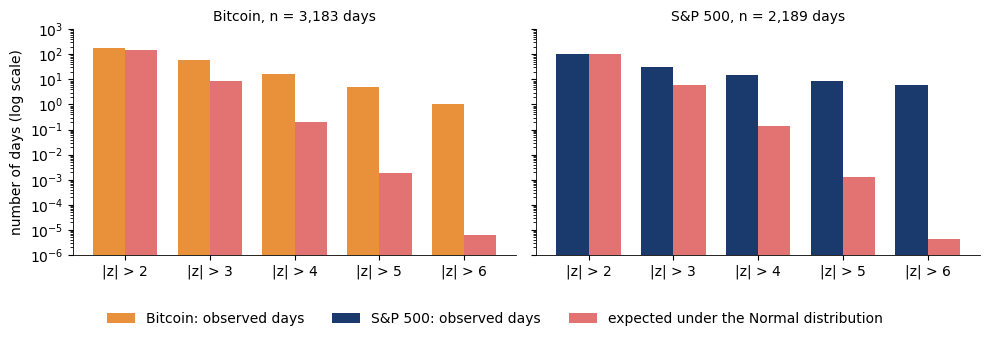

Bitcoin (n = 3,183)
   observed   Normal       ratio
2       185  144.827       1.277
3        59    8.593       6.866
4        17    0.202      84.317
5         5    0.002    2739.990
6         1    0.000  159220.027
S&P 500 (n = 2,189)
   observed  Normal        ratio
2        99  99.600        0.994
3        30   5.910        5.076
4        15   0.139      108.181
5         9   0.001     7171.540
6         6   0.000  1389120.181


In [6]:
# days beyond k standard deviations: observed against the Normal distribution, 2018-2026
K = [2, 3, 4, 5, 6]
crash = {}
for nm, sym in [('Bitcoin', 'BTC-USD.CC'), ('S&P 500', 'GSPC.INDX')]:
    r_ = log_returns(sym); z_ = (r_ - r_.mean()) / r_.std()
    crash[nm] = pd.DataFrame({'observed': [int((z_.abs() > k).sum()) for k in K],
                              'Normal': [len(r_) * 2 * stats.norm.sf(k) for k in K]}, index=K)
    crash[nm].attrs['n'] = len(r_)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
w_ = 0.38
for a_, (nm, col) in zip(ax, [('Bitcoin', BTC), ('S&P 500', BLUE)]):
    t_ = crash[nm]; x_ = np.arange(len(K))
    a_.bar(x_ - w_ / 2, t_['observed'].clip(lower=0.5), w_, color=col, label=f'{nm}: observed days')
    a_.bar(x_ + w_ / 2, t_['Normal'], w_, color=RED, alpha=0.55, label=('expected under the Normal distribution' if nm == 'S&P 500' else None))
    a_.set_xticks(x_); a_.set_xticklabels([f'|z| > {k}' for k in K]); a_.set_yscale('log'); a_.set_ylim(1e-6, 1e3)
    a_.set_title(f'{nm}, n = {t_.attrs["n"]:,} days', fontsize=10)
ax[0].set_ylabel('number of days (log scale)')
legend_below(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l2_crash_counts')
for nm, t_ in crash.items():
    print(nm, f'(n = {t_.attrs["n"]:,})')
    print((t_.assign(ratio=t_['observed'] / t_['Normal'])).round(3).to_string())

The expected counts for $k = 3$ and $k = 4$, and the waiting time between two days beyond 4 standard deviations.

In [7]:
# worked example: expected number of days beyond 3 and 4 standard deviations under the Normal distribution
n_ = crash['Bitcoin'].attrs['n']
for k in [3, 4]:
    p_ = 2 * stats.norm.sf(k)
    print(f'P(|z| > {k}) = 2 x {stats.norm.sf(k):.3e} = {p_:.3e}; expected days = {n_:,} x {p_:.3e} = {n_ * p_:.2f}; '
          f'observed (Bitcoin) {crash["Bitcoin"].loc[k, "observed"]}, ratio {crash["Bitcoin"].loc[k, "observed"] / (n_ * p_):.0f}')
print(f'Days between two |z| > 4 days: Normal {1 / (2 * stats.norm.sf(4)):,.0f} days ({1 / (2 * stats.norm.sf(4)) / 365:.0f} years); '
      f'observed {n_ / crash["Bitcoin"].loc[4, "observed"]:.0f} days')

P(|z| > 3) = 2 x 1.350e-03 = 2.700e-03; expected days = 3,183 x 2.700e-03 = 8.59; observed (Bitcoin) 59, ratio 7
P(|z| > 4) = 2 x 3.167e-05 = 6.334e-05; expected days = 3,183 x 6.334e-05 = 0.20; observed (Bitcoin) 17, ratio 84
Days between two |z| > 4 days: Normal 15,787 days (43 years); observed 187 days
